In [4]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Optional, Tuple, Dict, Any

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [15]:
@dataclass
class NaoEofVerifyConfig:
    base_nc: str
    fig_dir: str

    # Optional: original PSL file to re-project and verify PC1
    obs_psl_file: Optional[str] = None
    obs_var: Optional[str] = "psl"  # set None to auto-detect if needed

    # Expected definition (should match what you used to build)
    lat_bounds: Tuple[float, float] = (20.0, 80.0)
    lon_bounds: Tuple[float, float] = (-90.0, 40.0)
    months_ndjfm: Tuple[int, ...] = (11, 12, 1, 2, 3)

    # Verification tolerances
    pc_corr_warn: float = 0.999
    pc_rmse_warn: float = 1e-6


class NaoEofBaseVerifier:
    """
    Verify NAO EOF base file:
      - quick metadata + shape checks
      - EOF norm checks
      - plotting: EOF map, PC1 time series, PC1 histogram
      - optional: recompute anomalies/projection from obs file and compare to saved PC1
    """

    def __init__(self, cfg: NaoEofVerifyConfig):
        self.cfg = cfg
        self.fig_dir = Path(cfg.fig_dir)
        self.fig_dir.mkdir(parents=True, exist_ok=True)

        self.base = xr.open_dataset(cfg.base_nc)

    def close(self):
        try:
            self.base.close()
        except Exception:
            pass

    # -------------------------
    # Public entry
    # -------------------------
    def run_all(self) -> Dict[str, Any]:
        report: Dict[str, Any] = {}
        report["basic"] = self._basic_checks()
        report["eof_norm"] = self._check_eof_norm()
        report["plots"] = self._make_plots()

        if self.cfg.obs_psl_file is not None:
            report["projection_check"] = self._verify_projection_against_obs()

        return report

    # -------------------------
    # Checks
    # -------------------------
    def _basic_checks(self) -> Dict[str, Any]:
        ds = self.base
        required_vars = ["nao_eof1", "nao_pc1", "base_climatology", "explained_variance_fraction"]
        missing = [v for v in required_vars if v not in ds]
        if missing:
            raise KeyError(f"Missing variables in base file: {missing}. Present: {list(ds.data_vars)}")

        # dims
        eof = ds["nao_eof1"]
        pc1 = ds["nao_pc1"]
        clim = ds["base_climatology"]

        info = {
            "base_nc": self.cfg.base_nc,
            "eof_shape": tuple(eof.shape),
            "pc1_shape": tuple(pc1.shape),
            "clim_shape": tuple(clim.shape),
            "explained_variance_fraction": float(ds["explained_variance_fraction"].values),
            "attrs_dataset_name": ds.attrs.get("dataset_name", ""),
            "attrs_base_period": (ds.attrs.get("base_period_start", ""), ds.attrs.get("base_period_end", "")),
            "attrs_lat_bounds": ds.attrs.get("lat_bounds", ""),
            "attrs_lon_bounds": ds.attrs.get("lon_bounds", ""),
            "attrs_months_ndjfm": ds.attrs.get("months_ndjfm", ""),
        }

        # quick domain sanity (not strict, but helpful)
        lat = ds["lat"].values
        lon = ds["lon"].values
        info["lat_range"] = (float(np.nanmin(lat)), float(np.nanmax(lat)))
        info["lon_range"] = (float(np.nanmin(lon)), float(np.nanmax(lon)))
        info["pc1_time_range"] = (str(ds["time"].values[0]), str(ds["time"].values[-1]))

        return info

    def _check_eof_norm(self) -> Dict[str, Any]:
        eof = self.base["nao_eof1"].values
        norm = float(np.sqrt(np.nansum(eof**2)))
        frac = float(self.base["explained_variance_fraction"].values)

        # very small/very large frac indicates trouble
        flags = []
        if not np.isfinite(norm) or norm == 0:
            flags.append("EOF norm invalid (0 or non-finite).")
        # If you enforced unit norm, norm should be ~1
        # We don’t know for sure from file, but attrs have normalized_unit_norm
        normalized = str(self.base.attrs.get("normalized_unit_norm", "False")).lower() == "true"
        if normalized and abs(norm - 1.0) > 5e-3:
            flags.append(f"EOF unit-norm expected ~1 but got {norm:.6f}.")

        if not (0.0 < frac < 1.0):
            flags.append(f"explained_variance_fraction out of range: {frac}")

        return {"eof_l2_norm": norm, "normalized_unit_norm_attr": normalized, "flags": flags}

    # -------------------------
    # Plots
    # -------------------------
    def _make_plots(self) -> Dict[str, str]:
        out = {}
        out["eof_map"] = self._plot_eof_map()
        out["pc1_ts"] = self._plot_pc1_timeseries()
        out["pc1_hist"] = self._plot_pc1_histogram()
        return out

    def _plot_eof_map(self) -> str:
        ds = self.base
        eof = ds["nao_eof1"]

        fig = plt.figure(figsize=(9, 4.2))
        ax = plt.gca()
        # simple lon-lat plot (no cartopy dependency)
        im = ax.pcolormesh(ds["lon"], ds["lat"], eof, shading="auto")
        plt.colorbar(im, ax=ax, pad=0.02, label="EOF1 (unitless)")
        ax.set_title("NAO EOF1 (NDJFM, Atlantic sector)")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.set_xlim(float(ds["lon"].min()), float(ds["lon"].max()))
        ax.set_ylim(float(ds["lat"].min()), float(ds["lat"].max()))
        ax.grid(True, linewidth=0.4, alpha=0.5)

        # annotate variance explained + metadata
        frac = float(ds["explained_variance_fraction"].values)
        base0 = ds.attrs.get("base_period_start", "")
        base1 = ds.attrs.get("base_period_end", "")
        ax.text(
            0.01, 0.02,
            f"Explained var (EOF1): {frac:.3f}\nBase: {base0} to {base1}",
            transform=ax.transAxes,
            fontsize=9,
            va="bottom",
            ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.7, linewidth=0.5),
        )

        out_png = str(self.fig_dir / "NAO_EOF1_map.png")
        fig.tight_layout()
        fig.savefig(out_png, dpi=200)
        plt.close(fig)
        return out_png

    def _plot_pc1_timeseries(self) -> str:
        ds = self.base
        pc1 = ds["nao_pc1"]

        fig = plt.figure(figsize=(10, 3.6))
        ax = plt.gca()
        ax.plot(ds["time"].values, pc1.values, linewidth=0.8)
        ax.set_title("NAO PC1 (projection time series, NDJFM months)")
        ax.set_xlabel("Time")
        ax.set_ylabel("PC1 (Pa, weighted-space projection)")
        ax.grid(True, linewidth=0.4, alpha=0.5)

        out_png = str(self.fig_dir / "NAO_PC1_timeseries.png")
        fig.tight_layout()
        fig.savefig(out_png, dpi=200)
        plt.close(fig)
        return out_png

    def _plot_pc1_histogram(self) -> str:
        pc1 = self.base["nao_pc1"].values
        pc1 = pc1[np.isfinite(pc1)]

        fig = plt.figure(figsize=(6.5, 4.0))
        ax = plt.gca()
        ax.hist(pc1, bins=40)
        ax.set_title("NAO PC1 distribution (NDJFM months)")
        ax.set_xlabel("PC1 (Pa)")
        ax.set_ylabel("Count")
        ax.grid(True, linewidth=0.4, alpha=0.5)

        out_png = str(self.fig_dir / "NAO_PC1_hist.png")
        fig.tight_layout()
        fig.savefig(out_png, dpi=200)
        plt.close(fig)
        return out_png
        
    def _canonicalize_lonlat(self, da: xr.DataArray) -> xr.DataArray:
        # Ensure lon is in [-180, 180) and sorted
        da = self._to_lon180(da)
    
        # Round lon to kill float noise that breaks join='exact'
        if "lon" in da.coords:
            da = da.assign_coords(lon=np.round(da["lon"].values.astype(np.float64), 6))
            da = da.sortby("lon")
    
        # Round lat too (rarely needed but cheap & safe)
        if "lat" in da.coords:
            da = da.assign_coords(lat=np.round(da["lat"].values.astype(np.float64), 6))
            da = da.sortby("lat")
    
        return da
        
    def _to_lon180(self, da: xr.DataArray) -> xr.DataArray:
        if "lon" not in da.coords:
            return da
        lon = da["lon"].values
        if lon.ndim != 1:
            return da
        if np.nanmax(lon) > 180.0 + 1e-6:
            lon_new = ((lon + 180.0) % 360.0) - 180.0
            da = da.assign_coords(lon=lon_new).sortby("lon")
        return da
        
    # -------------------------
    # Optional: projection verification against obs PSL
    # -------------------------
    def _verify_projection_against_obs(self) -> Dict[str, Any]:
        ds_base = self.base
        eof = ds_base["nao_eof1"]
        clim = ds_base["base_climatology"]  # month, lat, lon
        months = set(self.cfg.months_ndjfm)
    
        obs = xr.open_dataset(self.cfg.obs_psl_file)
    
        # detect var if needed
        var = self.cfg.obs_var
        if var is None or var not in obs.data_vars:
            for cand in ("psl", "PSL", "slp", "SLP", "msl", "MSL", "PMSL", "pmsl"):
                if cand in obs.data_vars:
                    var = cand
                    break
        if var is None or var not in obs.data_vars:
            raise KeyError(f"Could not find PSL/SLP var in obs file. Available: {list(obs.data_vars)}")
    
        da = obs[var]
    
        # rename coordinates to match
        coord_map = {}
        for k in da.coords:
            lk = k.lower()
            if lk in ("latitude", "lat"):
                coord_map[k] = "lat"
            elif lk in ("longitude", "lon"):
                coord_map[k] = "lon"
            elif lk in ("time", "date"):
                coord_map[k] = "time"
        da = da.rename(coord_map)
    
        # --- Convert base fields to lon[-180,180] (define eof180!) ---
        da = self._to_lon180(da)
        eof180 = self._to_lon180(eof)
        clim180 = self._to_lon180(clim)
    
        # --- Subset domain first (reduces mismatch risk) ---
        lat0, lat1 = self.cfg.lat_bounds
        lon0, lon1 = self.cfg.lon_bounds
    
        if da["lat"][0] < da["lat"][-1]:
            da = da.sel(lat=slice(lat0, lat1))
        else:
            da = da.sel(lat=slice(lat1, lat0))
        da = da.sel(lon=slice(lon0, lon1))
    
        # NDJFM only
        da = da.sel(time=da["time"].dt.month.isin(list(months)))
    
        # --- Canonicalize after subsetting (rounding/sorting) ---
        da = self._canonicalize_lonlat(da)
        eof180 = self._canonicalize_lonlat(eof180)
        clim180 = self._canonicalize_lonlat(clim180)
    
        # --- Align obs to EOF grid ---
        try:
            da, eof180 = xr.align(da, eof180, join="exact")
        except Exception:
            # Fallback: interpolate obs onto EOF grid (verification only)
            da = da.interp(lat=eof180["lat"], lon=eof180["lon"])
            da, eof180 = xr.align(da, eof180, join="exact")
    
        # Align climatology onto same grid
        clim2 = clim180.sel(lat=da["lat"], lon=da["lon"])
    
        # anomalies relative to saved climatology
        anom = da.groupby("time.month") - clim2
    
        # weights (same as builder)
        w_sqrt = np.sqrt(np.cos(np.deg2rad(anom["lat"]))).clip(min=0.0)
        W = w_sqrt.broadcast_like(anom.isel(time=0))
        anom_w = anom * W
    
        # projection (EOF is in weighted space)
        pc_re = (anom_w * eof180).sum(("lat", "lon"))
    
        # Compare to saved PC1 on overlap times
        saved_pc = ds_base["nao_pc1"]
        pc_re, saved_pc = xr.align(pc_re, saved_pc, join="inner")
    
        x = pc_re.values
        y = saved_pc.values
        good = np.isfinite(x) & np.isfinite(y)
        x = x[good]
        y = y[good]
        
        # Fit y ≈ a*x + b (least squares) to diagnose pure scaling/offset
        A = np.vstack([x, np.ones_like(x)]).T
        a, b = np.linalg.lstsq(A, y, rcond=None)[0]
        
        y_fit = a * x + b
        rmse_fit = float(np.sqrt(np.mean((y_fit - y) ** 2)))
        
        # Also compute RMSE after rescaling x to match y (b usually tiny)
        rmse_rescaled = rmse_fit
        
        corr = float(np.corrcoef(x, y)[0, 1]) if x.size > 2 else np.nan
        rmse = float(np.sqrt(np.mean((x - y) ** 2))) if x.size > 0 else np.nan
    
        flags = []
        if np.isfinite(corr) and corr < self.cfg.pc_corr_warn:
            flags.append(f"PC1 correlation low: {corr:.6f} (expected ~1.0).")
        if np.isfinite(rmse) and rmse > self.cfg.pc_rmse_warn:
            flags.append(f"PC1 RMSE high: {rmse:.3e} (expected near 0).")
    
        # overlay plot
        fig = plt.figure(figsize=(10, 3.6))
        ax = plt.gca()
        ax.plot(pc_re["time"].values, pc_re.values, linewidth=0.8, label="Recomputed proj")
        ax.plot(saved_pc["time"].values, saved_pc.values, linewidth=0.8, label="Saved nao_pc1", alpha=0.8)
        ax.set_title(f"PC1 verification: corr={corr:.6f}, rmse={rmse:.3e}")
        ax.set_xlabel("Time")
        ax.set_ylabel("PC1 (Pa)")
        ax.grid(True, linewidth=0.4, alpha=0.5)
        ax.legend()
    
        out_png = str(self.fig_dir / "NAO_PC1_projection_check.png")
        fig.tight_layout()
        fig.savefig(out_png, dpi=200)
        plt.show()
        plt.close(fig)
    
        obs.close()
    
        return {
            "obs_file": self.cfg.obs_psl_file,
            "obs_var_used": var,
            "n_points": int(x.size),
            "pc_corr": corr,
            "pc_rmse": rmse,
            "plot": out_png,
            "flags": flags,
            "pc_corr": corr,
            "pc_rmse": rmse,
            "pc_scale_a": float(a),
            "pc_offset_b": float(b),
            "pc_rmse_after_linear_fit": rmse_fit,
        }



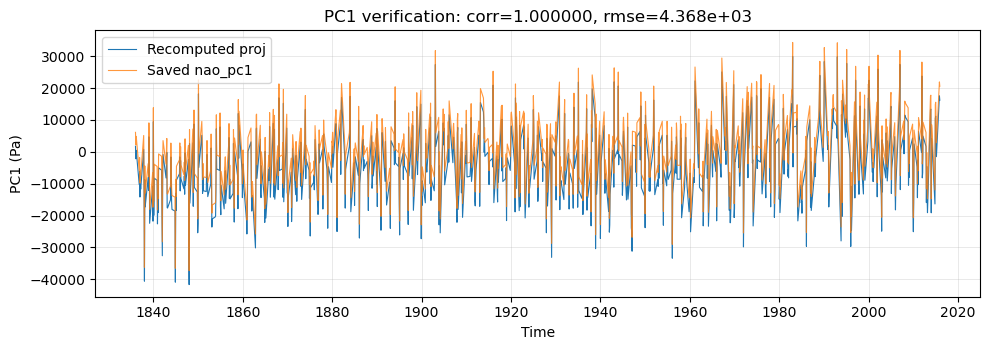

Verification report:

[basic]
{'base_nc': '/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/figure_data/nao/nao_eof_base_NOAA20C_1985-2014_NDJFM_20-80N_90W-40E.nc', 'eof_shape': (60, 40), 'pc1_shape': (900,), 'clim_shape': (5, 60, 40), 'explained_variance_fraction': 0.47832347646987833, 'attrs_dataset_name': 'NOAA-20C', 'attrs_base_period': ('1985-01-01', '2014-12-31'), 'attrs_lat_bounds': '(20.0, 80.0)', 'attrs_lon_bounds': '(-90.0, 40.0)', 'attrs_months_ndjfm': '11,12,1,2,3', 'lat_range': (20.5, 79.5), 'lon_range': (0.5, 39.5), 'pc1_time_range': ('1836-01-01T00:00:00.000000000', '2015-12-01T00:00:00.000000000')}

[eof_norm]
{'eof_l2_norm': 1.0, 'normalized_unit_norm_attr': True, 'flags': []}

[plots]
{'eof_map': '/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/figure_data/nao/verify_plots/NAO_EOF1_map.png', 'pc1_ts': '/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/figure_data/nao/verify_plots/NAO_PC1_timeseries.png', 'pc1_hist'

In [16]:
if __name__ == "__main__":
    diag_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    fig_dir = Path(diag_dir) / "figure_data" / "nao" / "verify_plots"
    fig_dir.mkdir(parents=True, exist_ok=True)

    base_nc = (
        "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper/"
        "figure_data/nao/nao_eof_base_NOAA20C_1985-2014_NDJFM_20-80N_90W-40E.nc"
    )

    cfg = NaoEofVerifyConfig(
        base_nc=base_nc,
        fig_dir=str(fig_dir),
        # Recommended: enable this to fully verify PC1 definition
        obs_psl_file="/lcrc/soft/climate/e3sm_diags_data/obs_for_e3sm_diags/time-series/NOAA-20C/psl_183601_201512.nc",
        obs_var="psl",  # set None if unsure
    )

    v = NaoEofBaseVerifier(cfg)
    report = v.run_all()
    v.close()

    print("Verification report:")
    for k, val in report.items():
        print(f"\n[{k}]")
        print(val)
    print(f"\nFigures written to: {fig_dir}")